In [1]:
import pandas as pd

df = pd.read_csv("../data/covid_19_clean_complete.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())

(49068, 10)
['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']
  Province/State Country/Region       Lat       Long        Date  Confirmed  \
0            NaN    Afghanistan  33.93911  67.709953  2020-01-22          0   
1            NaN        Albania  41.15330  20.168300  2020-01-22          0   
2            NaN        Algeria  28.03390   1.659600  2020-01-22          0   
3            NaN        Andorra  42.50630   1.521800  2020-01-22          0   
4            NaN         Angola -11.20270  17.873900  2020-01-22          0   

   Deaths  Recovered  Active             WHO Region  
0       0          0       0  Eastern Mediterranean  
1       0          0       0                 Europe  
2       0          0       0                 Africa  
3       0          0       0                 Europe  
4       0          0       0                 Africa  


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])

daily = (
    df.groupby("Date")[["Confirmed", "Deaths", "Recovered"]]
      .sum()
      .reset_index()
)

daily["New Cases"] = daily["Confirmed"].diff().fillna(0)
daily["New Recoveries"] = daily["Recovered"].diff().fillna(0)

daily.head()

,Date,Confirmed,Deaths,Recovered,New Cases,New Recoveries
0,2020-01-22,555,17,28,0.0,0.0
1,2020-01-23,654,18,30,99.0,2.0
2,2020-01-24,941,26,36,287.0,6.0
3,2020-01-25,1434,42,39,493.0,3.0
4,2020-01-26,2118,56,52,684.0,13.0


In [4]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=daily["Date"],
    y=daily["New Cases"],
    mode="lines",
    name="New Cases"
))

fig.add_trace(go.Scatter(
    x=daily["Date"],
    y=daily["New Recoveries"],
    mode="lines",
    name="New Recoveries"
))

fig.update_layout(
    title="COVID-19 Infection and Recovery Trend",
    xaxis_title="Date",
    yaxis_title="Number of Patients",
    hovermode="x unified"
)

fig.show()

In [13]:
impact = daily[["Date", "Confirmed", "Deaths", "Recovered"]].copy()

impact["Active Cases"] = (
    impact["Confirmed"]
    - impact["Deaths"]
    - impact["Recovered"]
)

impact["Death Rate (%)"] = (
    impact["Deaths"] / impact["Confirmed"] * 100
)

impact["Recovery Rate (%)"] = (
    impact["Recovered"] / impact["Confirmed"] * 100
)

impact["Infection Rate (%)"] = (
    daily["New Cases"] / daily["Confirmed"].shift(1) * 100
)

impact.tail()

,Date,Confirmed,Deaths,Recovered,Active Cases,Death Rate (%),Recovery Rate (%),Infection Rate (%)
183,2020-07-23,15510481,633506,8710969,6166006,4.084374,56.161824,1.856850
184,2020-07-24,15791645,639650,8939705,6212290,4.050560,56.610347,1.812736
185,2020-07-25,16047190,644517,9158743,6243930,4.016385,57.073812,1.618229
186,2020-07-26,16251796,648621,9293464,6309711,3.991073,57.184228,1.275027
187,2020-07-27,16480485,654036,9468087,6358362,3.968548,57.450293,1.407161


In [14]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=impact["Date"],
    y=impact["Confirmed"],
    mode="lines",
    name="Confirmed"
))

fig.add_trace(go.Scatter(
    x=impact["Date"],
    y=impact["Deaths"],
    mode="lines",
    name="Deaths"
))

fig.add_trace(go.Scatter(
    x=impact["Date"],
    y=impact["Recovered"],
    mode="lines",
    name="Recovered"
))

fig.update_layout(
    title="COVID-19 Impact: Confirmed, Deaths and Recovered Cases",
    xaxis_title="Date",
    yaxis_title="Number of Patients",
    hovermode="x unified"
)

fig.show()

In [15]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=impact["Date"],
    y=impact["Death Rate (%)"],
    mode="lines",
    name="Death Rate"
))

fig.add_trace(go.Scatter(
    x=impact["Date"],
    y=impact["Recovery Rate (%)"],
    mode="lines",
    name="Recovery Rate"
))

fig.add_trace(go.Scatter(
    x=impact["Date"],
    y=impact["Infection Rate (%)"],
    mode="lines",
    name="Infection Rate"
))

fig.update_layout(
    title="COVID-19 Death and Recovery Rates",
    xaxis_title="Date",
    yaxis_title="Rate (%)",
    hovermode="x unified"
)

fig.show()

In [7]:
from prophet import Prophet

forecast_df = daily[["Date", "Confirmed"]].copy()
forecast_df.columns = ["ds", "y"]

model = Prophet()
model.fit(forecast_df)

19:35:05 - cmdstanpy - INFO - Chain [1] start processing
19:35:05 - cmdstanpy - INFO - Chain [1] done processing


In [8]:
future = model.make_future_dataframe(
    periods=7,
    freq="D"
)

forecast = model.predict(future)

prediction = forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(7)

prediction

,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.632012e+07,1.621274e+07,1.642112e+07
189,2020-07-29,1.652995e+07,1.642293e+07,1.664223e+07
190,2020-07-30,1.674386e+07,1.664556e+07,1.685294e+07
191,2020-07-31,1.695903e+07,1.684250e+07,1.706573e+07
192,2020-08-01,1.716674e+07,1.704898e+07,1.727801e+07
193,2020-08-02,1.736429e+07,1.724951e+07,1.747428e+07
194,2020-08-03,1.755891e+07,1.745383e+07,1.766962e+07


C:\Users\vihan\AppData\Local\Temp\ipykernel_4408\2107326233.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


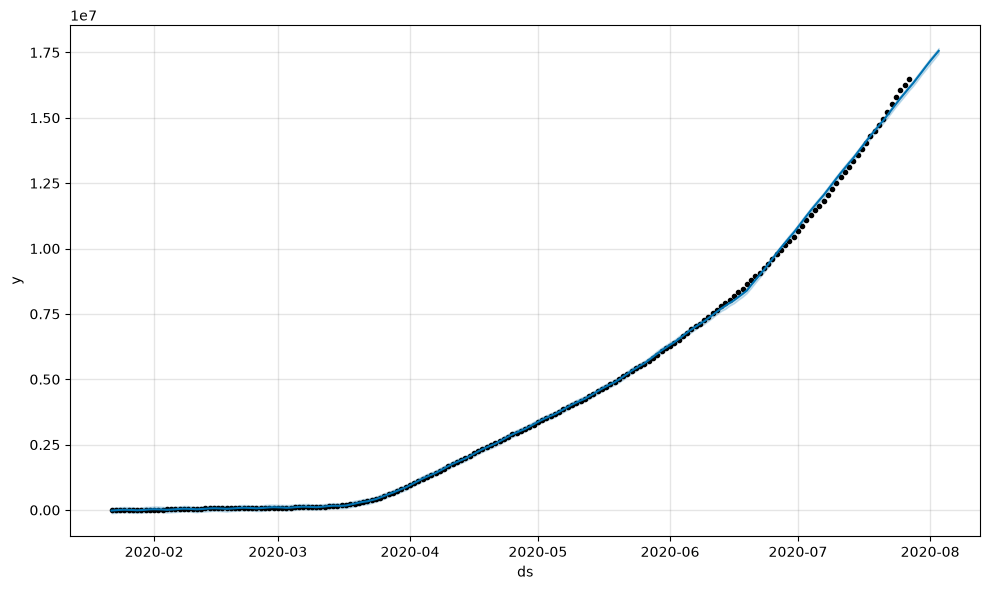

In [9]:
fig = model.plot(forecast)
fig.show()

In [10]:
print("Dataset shape:", df.shape)
print("Daily records:", len(daily))
print("\nLatest global totals:")
display(impact.tail(1))

print("\n1-week forecast:")
display(prediction)

Dataset shape: (49068, 10)
Daily records: 188

Latest global totals:


,Date,Confirmed,Deaths,Recovered,Active Cases,Death Rate (%),Recovery Rate (%)
187,2020-07-27,16480485,654036,9468087,6358362,3.968548,57.450293



1-week forecast:


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.632012e+07,1.621274e+07,1.642112e+07
189,2020-07-29,1.652995e+07,1.642293e+07,1.664223e+07
190,2020-07-30,1.674386e+07,1.664556e+07,1.685294e+07
191,2020-07-31,1.695903e+07,1.684250e+07,1.706573e+07
192,2020-08-01,1.716674e+07,1.704898e+07,1.727801e+07
193,2020-08-02,1.736429e+07,1.724951e+07,1.747428e+07
194,2020-08-03,1.755891e+07,1.745383e+07,1.766962e+07
